# Практическая работа № 5 — Классификатор и анализ метрик
**Вариант A**

Для учебного примера создаём бинарную цель: высокий счёт (`total_bill` выше медианы).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

candidates = [Path("data/tips_sample.csv"), Path("../data/tips_sample.csv")]
df = pd.read_csv(next(p for p in candidates if p.exists())).dropna(subset=["total_bill"]).copy()
df["high_bill"] = (df["total_bill"] > df["total_bill"].median()).astype(int)
X = df.drop(columns=["high_bill", "total_bill"])
y = df["high_bill"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


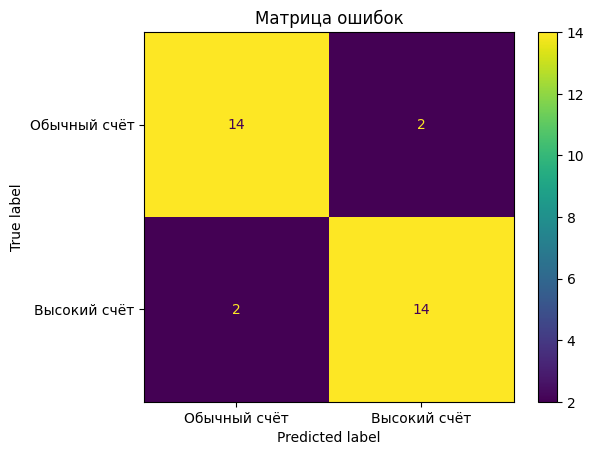

TN, FP, FN, TP: [14  2  2 14]


In [2]:
num_cols = ["size", "tip"]
cat_cols = ["day", "time"]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
model = Pipeline([("preprocessor", preprocessor), ("classifier", LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)
pred = model.predict(X_test)
cm = confusion_matrix(y_test, pred, labels=[0,1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Обычный счёт", "Высокий счёт"])
disp.plot()
plt.title("Матрица ошибок")
plt.show()
print("TN, FP, FN, TP:", cm.ravel())


In [3]:
print(f"Accuracy:  {accuracy_score(y_test, pred):.3f}")
print(f"Precision: {precision_score(y_test, pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, pred, zero_division=0):.3f}")
print(f"F1:        {f1_score(y_test, pred, zero_division=0):.3f}")


Accuracy:  0.875
Precision: 0.875
Recall:    0.875
F1:        0.875


## Интерпретация ячеек матрицы
- **TP:** высокий счёт правильно предсказан как высокий.
- **FP:** обычный счёт ошибочно предсказан как высокий.
- **TN:** обычный счёт правильно предсказан как обычный.
- **FN:** высокий счёт ошибочно предсказан как обычный.

**Выбор метрики:** для поиска как можно большего числа высоких счетов важен recall; если ложные тревоги тоже нежелательны, нужно смотреть на precision и F1. Это учебная демонстрация, а не прикладная финансовая модель.